# 06 · Speed and candidate shaking

**Why:** the video experiments did not isolate whether shaking adds useful information.  
**Question:** does adding a dedicated high-frequency movement signal improve a matched speed-only model?

These measurements are candidate video shaking, not sensor-validated physiological tremor. Pose locates regions; pixel movement supplies the signal. Run All reads saved results.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "training/notebooks").is_dir()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from training.reporting import (
    RUNS,
    LABELS,
    result_folder,
    load_predictions,
    assert_matched_examples,
    regression_report,
    classification_report,
    metrics_table,
    plot_errors,
    plot_participants,
    plot_diagnostics,
    plot_warnings,
)

OUTPUT = ROOT / "training/artifacts/submission_report"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 44)


## Experiment 7 · Original pixel-motion signal

**Change:** estimate wrist-region optical flow, subtract background camera motion, and normalize by shoulder width. The last four completed reps supply speed below 3 Hz and candidate shaking at 4–10 Hz. Compare regularized regressors on identical accepted examples.

**Coverage:** 97 examples from six people were screened; only 33 examples from four people passed tracking quality. One person has only one accepted example. This selected subset is not directly comparable with the earlier 124-rep results.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Initial shaking · selected subset,Speed only,33,4,1,2.251,0.0,2.651,0.402,0.553,-0.385,-0.297,3
1,Initial shaking · selected subset,Speed + original shaking,33,4,1,2.882,0.0,3.361,0.152,0.288,-0.534,-0.794,3
2,Initial shaking · selected subset,Training median,33,4,1,2.453,0.0,2.923,0.458,0.574,0.042,-0.675,3


,accepted,screened
participant_id,,
P001,12,21
P002,1,15
P003,13,24
P005,7,7
P006,0,26
P012,0,4


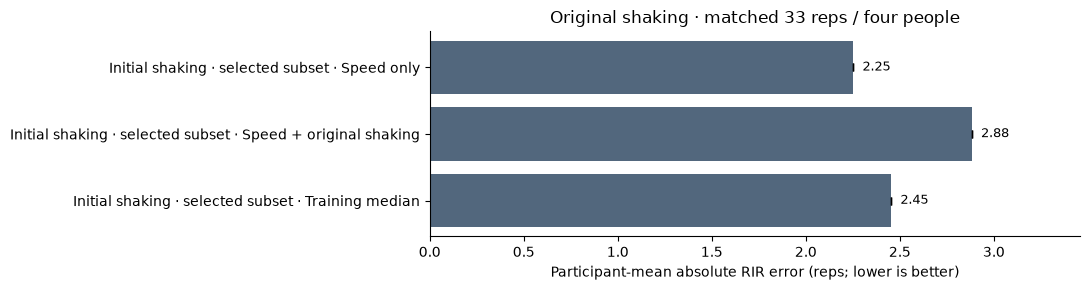

In [2]:
shaking_predictions = load_predictions(
    ROOT, "shaking", "Initial shaking · selected subset"
)
assert_matched_examples(shaking_predictions)
shaking_scores, shaking_people = regression_report(shaking_predictions)
display(metrics_table(shaking_scores))
quality = pd.read_csv(result_folder(ROOT, "shaking") / "quality.csv")
display(quality.groupby("participant_id").accepted.agg(accepted="sum", screened="size"))
plot_errors(
    shaking_scores,
    "Original shaking · matched 33 reps / four people",
    OUTPUT / "06_original_shaking.png",
)
plt.show()
shaking_scores.to_csv(OUTPUT / "06_original_shaking_metrics.csv", index=False)


**Result:** adding original shaking increased MAE from 2.25 to 2.88 reps. No improvement was demonstrated.

**Next question:** is changing the tracked image points each frame introducing unwanted variation?

## Experiment 8 · Persistent points and transverse shaking

**Change:** keep image points across frames. Test both 2D shaking and shaking across the main slow lifting direction. Keep the original speed inputs, test examples and participant folds fixed. A rigid local-affine variant failed coverage; it is preserved in the artifacts and was not scored. The final variant permits nonrigid point motion.

This follow-up was chosen after inspecting earlier results and is exploratory, not an untouched confirmation test. It is inspired by [large-motion separation research](https://arxiv.org/html/1809.03218), not a replication of that paper's phase-pyramid method.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Persistent shaking · same subset,Speed only,33,4,1,2.251,0.0,2.651,0.402,0.553,-0.385,-0.297,3
1,Persistent shaking · same subset,Speed + original shaking,33,4,1,2.882,0.0,3.361,0.152,0.288,-0.534,-0.794,3
2,Persistent shaking · same subset,Speed + persistent 2D shaking,33,4,1,2.734,0.0,3.235,0.400,0.531,0.157,-1.024,3
3,Persistent shaking · same subset,Speed + transverse shaking,33,4,1,2.221,0.0,2.645,0.402,0.553,-0.261,-0.417,3
4,Persistent shaking · same subset,Training median,33,4,1,2.453,0.0,2.923,0.458,0.574,0.042,-0.675,3


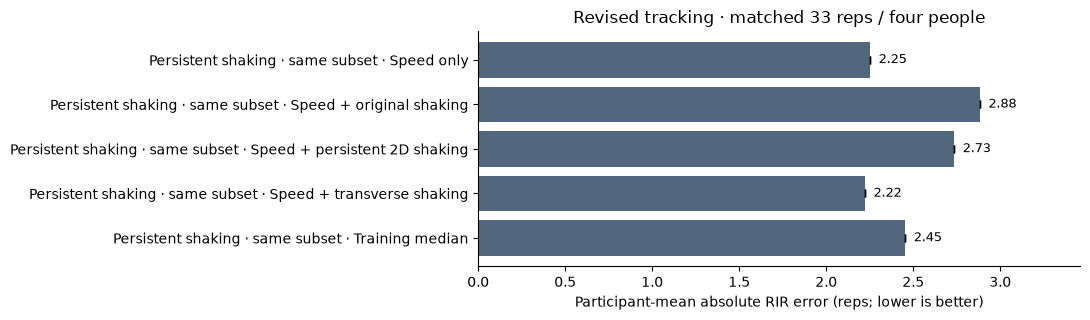

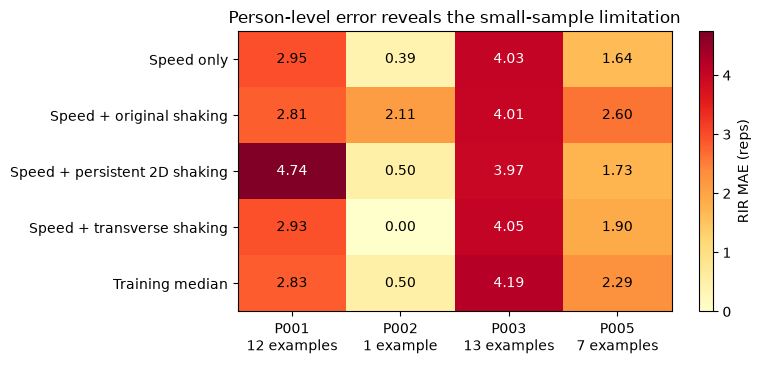

Relative MAE reduction: 1.32% (target: 15%).


In [3]:
persistent_predictions = load_predictions(
    ROOT, "persistent", "Persistent shaking · same subset"
)
assert_matched_examples(persistent_predictions)
persistent_scores, persistent_people = regression_report(persistent_predictions)
display(metrics_table(persistent_scores))
plot_errors(
    persistent_scores,
    "Revised tracking · matched 33 reps / four people",
    OUTPUT / "06_revised_shaking.png",
)
plt.show()
plot_participants(
    persistent_people,
    "Person-level error reveals the small-sample limitation",
    OUTPUT / "06_person_errors.png",
)
plt.show()
speed_mae = persistent_scores.loc[
    persistent_scores.model.eq("speed_only"), "mae"
].item()
revised_mae = persistent_scores.loc[
    persistent_scores.model.eq("speed_plus_persistent_transverse"), "mae"
].item()
print(
    f"Relative MAE reduction: {100*(speed_mae-revised_mae)/speed_mae:.2f}% (target: 15%)."
)
persistent_scores.to_csv(OUTPUT / "06_revised_shaking_metrics.csv", index=False)
persistent_people.to_csv(OUTPUT / "06_revised_shaking_participants.csv", index=False)


**Result:** transverse shaking reached about 2.22 reps MAE, a 1.32% reduction from speed alone. This does not meet the 15% target. Most of the numerical gain comes from the person with only one accepted example.

In [4]:
single_example_people = (
    persistent_people.groupby("participant_id")
    .examples.first()
    .loc[lambda x: x < 2]
    .index
)
sensitivity_predictions = persistent_predictions.loc[
    ~persistent_predictions.participant_id.isin(single_example_people)
].copy()
sensitivity_predictions["condition"] = "Sensitivity · exclude single-example person"
sensitivity_scores, _ = regression_report(sensitivity_predictions)
display(metrics_table(sensitivity_scores))
sensitivity_scores.to_csv(OUTPUT / "06_sensitivity_metrics.csv", index=False)
checks = json.loads(
    (result_folder(ROOT, "persistent") / "controlled_signal_checks.json").read_text()
)
display(
    pd.DataFrame(
        {key: value for key, value in checks.items() if isinstance(value, dict)}
    ).T.round(6)
)


,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Sensitivity · exclude single-example person,Speed only,32,3,1,2.871,0.0,3.404,0.202,0.404,-0.644,-0.297,3
1,Sensitivity · exclude single-example person,Speed + original shaking,32,3,1,3.140,0.0,3.779,0.202,0.384,-1.414,-0.794,3
2,Sensitivity · exclude single-example person,Speed + persistent 2D shaking,32,3,1,3.480,0.0,4.148,0.200,0.374,0.044,-1.024,3
3,Sensitivity · exclude single-example person,Speed + transverse shaking,32,3,1,2.962,0.0,3.527,0.202,0.404,-0.348,-0.417,3
4,Sensitivity · exclude single-example person,Training median,32,3,1,3.104,0.0,3.731,0.277,0.432,-0.111,-0.675,3


,peak_hz,normalized_rms
hand_shaking,6.0,0.004106
camera_shaking_only,6.0,0.000143


**Lesson:** after excluding the single-example person, error rises from 2.87 (speed) to 2.96 (revised shaking). The apparent gain is fragile. Controlled fixtures recovered a tiny 6 Hz shake and suppressed camera-only shaking, but they do not validate tremor in exercise footage. Compression, blur, body motion and optical-flow error remain possible confounders.

**Conclusion for this question:** a reliable 15% benefit from adding tremor has not been demonstrated. Keep the original result and the sensitivity check together.

## Reading the metrics

Metrics average each participant equally, then average training seeds. **MAE** is mean absolute error in reps; **RMSE** gives more weight to large errors. **Within 1/2** is the fraction within one/two reps. **Bias** is predicted minus known RIR: positive means too many reps predicted. R² compares with variation in known RIR; it can be negative and is undefined for a person with only one example. Seed standard deviation is not a confidence interval; one seed gives no estimate of training variability.

## Reproduce signal experiments · optional

The following support cells separate tracking, signal features and matched evaluation. No application model is exported.

In [5]:
RUN_CANDIDATE_TREMOR = False
RUN_PERSISTENT_TREMOR = False

In [6]:
from app.backend.services.motion_features import candidate_features, flow_vectors, pixel_motion, transverse_shaking, tremor_hash

from pathlib import Path

from datetime import datetime, timezone

import hashlib

import json

import cv2

import numpy as np

import pandas as pd

from scipy.signal import welch, butter, sosfiltfilt

from sklearn.pipeline import make_pipeline

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge, LogisticRegression

from sklearn.metrics import mean_absolute_error, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import matplotlib.pyplot as plt

def locate_pose_cache(root, video, source_hash, batch, cache):
    matches = batch.loc[batch.relative_path.eq(video.name)]
    if len(matches)==1:
        directory = Path(matches.iloc[0].cache_dir)
        meta = json.loads((directory/'analysis.json').read_text())
        if meta.get('source_sha256') == source_hash:
            return directory/'frames.csv'
    output = cache/(source_hash+'_roi_pose.csv')
    if output.exists():
        return output
    import mediapipe as mp
    model = root/'training/models/pose_landmarker_heavy.task'
    options = mp.tasks.vision.PoseLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(model)),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,num_poses=1)
    capture = cv2.VideoCapture(str(video)); rows=[]; previous_ms=-1
    try:
        with mp.tasks.vision.PoseLandmarker.create_from_options(options) as detector:
            while True:
                ok,frame=capture.read()
                if not ok:
                    break
                if frame.shape[1]>960:
                    frame=cv2.resize(frame,(960,round(frame.shape[0]*960/frame.shape[1])))
                rgb=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
                ms=round(capture.get(cv2.CAP_PROP_POS_MSEC))
                if ms<=previous_ms:
                    raise ValueError('Nonmonotonic video frame times.')
                previous_ms=ms
                result=detector.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB,data=rgb),ms)
                row={'time_s':ms/1000}
                for side,indices in [('left',(11,13,15)),('right',(12,14,16))]:
                    for joint in ('shoulder','elbow','wrist'):
                        for axis in ('x','y'):
                            row[f'{side}_{joint}_{axis}']=np.nan
                    if not result.pose_landmarks:
                        continue
                    points=[result.pose_landmarks[0][i] for i in indices]
                    if min(p.visibility for p in points)<.6:
                        continue
                    shoulder=points[0]
                    for joint,point in zip(('shoulder','elbow','wrist'),points):
                        row[f'{side}_{joint}_x']=point.x-(shoulder.x if joint!='shoulder' else 0)
                        row[f'{side}_{joint}_y']=point.y-(shoulder.y if joint!='shoulder' else 0)
                rows.append(row)
    finally:
        capture.release()
    pd.DataFrame(rows).to_csv(output,index=False)
    return output

In [7]:
from app.backend.services.motion_features import (
    candidate_features,
    flow_vectors,
    pixel_motion,
    transverse_shaking,
    tremor_hash,
)


In [8]:
def matched_signal_comparison(table, folds, output, feature_groups=None, tasks=('rir','near_failure')):
    speed = ['speed_mean','speed_p90','speed_current','speed_change']
    shaking = ['candidate_log_rms','candidate_power_fraction','candidate_peak_fraction']
    predictions = []; selections = []
    def fit_model(train,columns,task,regularization):
        model = (Ridge(alpha=regularization) if task=='rir' else
                 LogisticRegression(C=regularization,class_weight='balanced',solver='liblinear',max_iter=1000,random_state=42))
        pipe = make_pipeline(StandardScaler(),model)
        weights = (1/train.groupby('participant_id').participant_id.transform('size')).to_numpy(copy=True)
        weights *= len(weights)/weights.sum()
        step = 'ridge' if task=='rir' else 'logisticregression'
        y = train.reps_left if task=='rir' else train.reps_left.le(2).astype(int)
        pipe.fit(train[columns],y,**{step+'__sample_weight':weights})
        return pipe
    def score(test,values,task):
        scores = []
        for person,group in test.groupby('participant_id',sort=False):
            loc = test.participant_id.eq(person).to_numpy(); truth = group.reps_left.to_numpy()
            scores.append(mean_absolute_error(truth,values[loc]) if task=='rir' else
                          balanced_accuracy_score(truth<=2,values[loc]>=.5))
        return float(np.mean(scores))
    for fold in folds:
        train = table.loc[table.participant_id.isin(fold['outer_train_participants'])]
        test = table.loc[table.participant_id.isin(fold['test_participants'])]
        if test.empty:
            continue
        for task in tasks:
            if task=='near_failure' and any(g.reps_left.le(2).nunique()<2 for _,g in table.groupby('participant_id')):
                print('Classification not scored: quality filtering removed one class for a participant.',flush=True)
                continue
            for name,columns in (feature_groups or [('speed_only',speed),('speed_plus_candidate_tremor',speed+shaking)]):
                candidates = []
                for regularization in ([.1,1.,10.,100.] if task=='rir' else [.01,.1,1.,10.]):
                    scores = []
                    for inner in fold['inner_validation']:
                        a = train.loc[train.participant_id.isin(inner['train_participants'])]
                        b = train.loc[train.participant_id.isin(inner['validation_participants'])]
                        if a.empty or b.empty:
                            continue
                        model = fit_model(a,columns,task,regularization)
                        v = model.predict(b[columns]) if task=='rir' else model.predict_proba(b[columns])[:,1]
                        scores.append(score(b,v,task))
                    if scores:
                        candidates.append((float(np.mean(scores)),regularization))
                if not candidates:
                    raise ValueError('No valid inner participant folds.')
                selected = min(candidates)[1] if task=='rir' else max(candidates,key=lambda x:x[0])[1]
                model = fit_model(train,columns,task,selected)
                values = model.predict(test[columns]) if task=='rir' else model.predict_proba(test[columns])[:,1]
                record = test[['sample_id','participant_id','video_id','rep','reps_left']].copy()
                record['prediction'] = values;record['model'] = name;record['task'] = task
                predictions.append(record)
                selections.append({'fold_id':fold['fold_id'],'task':task,'model':name,'regularization':selected})
            record = test[['sample_id','participant_id','video_id','rep','reps_left']].copy()
            record['prediction'] = float(train.reps_left.median()) if task=='rir' else 0.
            record['model'] = 'training_median' if task=='rir' else 'always_far';record['task'] = task
            predictions.append(record)
    predictions = pd.concat(predictions,ignore_index=True)
    predictions.to_csv(output/'predictions.csv',index=False)
    pd.DataFrame(selections).to_csv(output/'inner_selection.csv',index=False)
    scores = []
    for (task,name,person),group in predictions.groupby(['task','model','participant_id']):
        row = {'task':task,'model':name,'participant_id':person,'examples':len(group)}
        if task=='rir':
            row['mae'] = mean_absolute_error(group.reps_left,group.prediction)
        else:
            truth = group.reps_left.le(2);guess = group.prediction.ge(.5)
            tn,fp,fn,tp = confusion_matrix(truth,guess,labels=[False,True]).ravel()
            row.update(balanced_accuracy=balanced_accuracy_score(truth,guess),precision=precision_score(truth,guess,zero_division=0),
                       recall=recall_score(truth,guess,zero_division=0),specificity=tn/(tn+fp),f1=f1_score(truth,guess,zero_division=0))
        scores.append(row)
    scores = pd.DataFrame(scores); scores.to_csv(output/'participant_scores.csv',index=False)
    comparison = scores.groupby(['task','model']).mean(numeric_only=True)
    comparison.to_csv(output/'comparison.csv')
    return comparison

In [9]:
def run_tremor_comparison(root):
    cv2.setNumThreads(2)
    prepared = root/'training/data/prepared/history_4_reps/9f528c70e2c385f0'
    windows = pd.read_csv(prepared/'windows.csv')
    marks = pd.read_csv(root/'training/data/processed/reviewed_reps.csv')
    batch = pd.read_csv(root/'training/data/review/batch_summary.csv')
    folds = json.loads((prepared/'folds.json').read_text())
    output = root/'training/artifacts'/('candidate_tremor_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
    output.mkdir(parents=True)
    (root/'training/artifacts/LATEST_TREMOR_BATCH.txt').write_text(str(output)+'\n')
    (output/'status.json').write_text(json.dumps({'status':'running','stage':'pixel extraction'}))
    cache = root/'training/data/review/pixel_motion'; cache.mkdir(exist_ok=True)
    rows = []; quality = []; provenance = []
    for video_id,group in windows.groupby('video_id',sort=False):
        print('Extracting wrist pixels:',video_id,flush=True)
        relative = group.relative_path.iloc[0]
        video = root/'training/data/videos'/relative
        annotation = marks.loc[marks.video_id.eq(video_id)].sort_values('rep')
        source_hash = tremor_hash(video)
        if set(annotation.video_sha256) != {source_hash}:
            raise ValueError(f'{video_id}: annotation/source hash mismatch.')
        pose_path = locate_pose_cache(root,video,source_hash,batch,cache)
        flow = pixel_motion(video,pose_path,cache/(video_id+'.csv'))
        provenance.append({'video_id':video_id,'video_sha256':source_hash,'pose_sha256':tremor_hash(pose_path)})
        flow.iloc[::5].to_csv(output/(video_id+'_motion_preview.csv'),index=False)
        for row in group.loc[group.rep.ge(4)].itertuples():
            history = annotation.loc[annotation.rep.between(row.rep-3,row.rep)]
            if len(history)!=4:
                raise ValueError('Missing reviewed four-rep history.')
            result,reason = candidate_features(flow,float(history.start_s.min()),float(history.end_s.max()),float(history.start_s.iloc[-1]))
            quality.append({'sample_id':row.sample_id,'video_id':video_id,'participant_id':row.participant_id,'rep':row.rep,'accepted':result is not None,'reason':reason or ''})
            if result is not None:
                rows.append({**row._asdict(),**result})
        print(video_id,'accepted',sum(r['video_id']==video_id for r in rows),'of',sum(group.rep.ge(4)),flush=True)
        pd.DataFrame(quality).to_csv(output/'quality.csv',index=False)
    table = pd.DataFrame(rows)
    table.to_csv(output/'features.csv',index=False)
    if table.empty or table.participant_id.nunique()<3:
        raise ValueError('Too few participants pass optical-flow signal quality. No fabricated/imputed tremor results.')
    assert not table.sample_id.duplicated().any() and table.rep.ge(4).all()
    comparison = matched_signal_comparison(table,folds,output)
    configuration = {'feature_family':'camera-compensated wrist-region optical flow; pose only locates ROI',
        'band_hz':[4,10],'speed_lowpass_hz':3,'history':'four completed reps only','max_image_dimension':1280,
        'target':'RIR from reviewed failure endpoints; secondary RIR<=2',
        'evaluation':'same quality-passing examples and outer people; nested participant regularization; fixed 0.5 classification threshold',
        'source_hashes':provenance,'windows_sha256':tremor_hash(prepared/'windows.csv'),
        'labels_sha256':tremor_hash(root/'training/data/processed/reviewed_reps.csv'),
        'candidate_examples':97,'accepted_examples':len(table),'participants':int(table.participant_id.nunique()),
        'limitations':'Not validated physiological tremor. Optical-flow error, body sway, camera/parallax, compression and blur can produce high-frequency energy. Whole-rep filtering is retrospective within the completed history. Original targets and app unchanged.',
        'reference':'https://pmc.ncbi.nlm.nih.gov/articles/PMC11192937/','deployment_approved':False}
    (output/'config.json').write_text(json.dumps(configuration,indent=2))
    fig,axes = plt.subplots(1,2,figsize=(9,3.5))
    for name,group in table.groupby('participant_id'):
        axes[0].scatter(group.reps_left,group.candidate_log_rms,s=13,label=name,alpha=.65)
    axes[0].set(xlabel='Known RIR',ylabel='Log10 candidate shaking RMS / shoulder width')
    axes[0].legend(fontsize=7)
    regression = comparison.loc['rir','mae']
    axes[1].bar(range(len(regression)),regression.to_numpy())
    axes[1].set_xticks(range(len(regression)),[x.replace('_','\n') for x in regression.index],fontsize=7)
    axes[1].set(ylabel='Participant-mean MAE (lower is better)')
    fig.tight_layout();fig.savefig(output/'comparison.png',dpi=160);plt.close(fig)
    import wandb
    run=wandb.init(project='replens',mode='offline',dir=str(output),name='candidate-tremor-matched-comparison',
        config={k:v for k,v in configuration.items() if k!='source_hashes'},
        settings=wandb.Settings(disable_git=True,disable_code=True,save_code=False,x_disable_stats=True))
    try:
        run.log({f'{task}/{model}/{metric}':float(value) for (task,model),row in comparison.iterrows()
                 for metric,value in row.items() if np.isfinite(value)})
    finally:
        run.finish()
    (output/'status.json').write_text(json.dumps({'status':'completed','results_dir':str(output),'accepted_examples':len(table),'participants':int(table.participant_id.nunique())},indent=2))
    print(comparison.to_string(),flush=True)
    print('Completed:',output,flush=True)
    return output

In [10]:
from app.backend.services.motion_features import (
    candidate_features,
    flow_vectors,
    pixel_motion,
    transverse_shaking,
    tremor_hash,
)


In [11]:
def run_persistent_comparison(root, reference):
    cv2.setNumThreads(2)
    original=pd.read_csv(reference/'features.csv')
    marks=pd.read_csv(root/'training/data/processed/reviewed_reps.csv')
    batch=pd.read_csv(root/'training/data/review/batch_summary.csv')
    folds=json.loads((root/'training/data/prepared/history_4_reps/9f528c70e2c385f0/folds.json').read_text())
    output=root/'training/artifacts'/('persistent_tremor_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
    output.mkdir(parents=True)
    (root/'training/artifacts/LATEST_PERSISTENT_TREMOR_BATCH.txt').write_text(str(output)+'\n')
    (output/'status.json').write_text(json.dumps({'status':'running','reference':str(reference)}))
    cache=root/'training/data/review/pixel_motion';rows=[];quality=[];sources=[]
    for video_id,group in original.groupby('video_id',sort=False):
        print('Persistent point tracking:',video_id,flush=True)
        video=root/'training/data/videos'/group.relative_path.iloc[0]
        annotations=marks.loc[marks.video_id.eq(video_id)].sort_values('rep')
        source_hash=tremor_hash(video)
        if set(annotations.video_sha256)!={source_hash}:
            raise ValueError('Source/label hash mismatch.')
        pose=locate_pose_cache(root,video,source_hash,batch,cache)
        flow=pixel_motion(video,pose,cache/(video_id+'_persistent_v3.csv'),persistent=True)
        sources.append({'video_id':video_id,'source_sha256':source_hash,'pose_sha256':tremor_hash(pose)})
        for row in group.itertuples():
            history=annotations.loc[annotations.rep.between(row.rep-3,row.rep)]
            assert len(history)==4
            features,reason=transverse_shaking(flow,float(history.start_s.min()),float(history.end_s.max()),float(history.start_s.iloc[-1]))
            quality.append({'sample_id':row.sample_id,'video_id':video_id,'participant_id':row.participant_id,'rep':row.rep,'accepted':features is not None,'reason':reason or ''})
            if features is not None:
                rows.append({**row._asdict(),**features})
        print(video_id,'matched examples',sum(r['video_id']==video_id for r in rows),'/',len(group),flush=True)
        pd.DataFrame(quality).to_csv(output/'quality.csv',index=False)
    table=pd.DataFrame(rows);table.to_csv(output/'features.csv',index=False)
    config={'reference_run':str(reference),'reference_examples':len(original),'accepted_examples':len(table),
        'participants':int(table.participant_id.nunique()) if not table.empty else 0,
        'method':'persistent forward-backward checked image points; robust median point displacement minus background affine; transverse projection relative to 1.5 Hz main-movement PCA axis',
        'comparison':'original speed inputs unchanged; old, persistent-2D and persistent-transverse 4–10 Hz features; same quality-passing examples for every method',
        'reference_features_sha256':tremor_hash(reference/'features.csv'),'sources':sources,
        'regularization':[.1,1,10,100],'evaluation':'nested leave-person-out Ridge; no outer-test tuning',
        'research':'https://arxiv.org/html/1809.03218',
        'limitations':'Exploratory follow-up after inspecting previous results, not an untouched confirmation set. Not a replication of phase-pyramid research. No sensor reference. Small selected subset and uneven people. No app promotion.',
        'deployment_approved':False}
    (output/'config.json').write_text(json.dumps(config,indent=2))
    if table.empty or table.participant_id.nunique()<3:
        (output/'status.json').write_text(json.dumps({'status':'insufficient_quality','results_dir':str(output)}))
        print('Too few people pass tracking checks; no valid matched model comparison.',flush=True)
        return output
    speed=['speed_mean','speed_p90','speed_current','speed_change']
    groups=[('speed_only',speed),
        ('speed_plus_original_shaking',speed+['candidate_log_rms','candidate_power_fraction','candidate_peak_fraction']),
        ('speed_plus_persistent_2d',speed+['persistent_log_rms','persistent_power_fraction','persistent_peak_fraction']),
        ('speed_plus_persistent_transverse',speed+['transverse_log_rms','transverse_power_fraction','transverse_peak_fraction'])]
    comparison=matched_signal_comparison(table,folds,output,feature_groups=groups,tasks=('rir',))
    comparison.loc['rir','mae'].plot.bar(figsize=(8,3.6),ylabel='Participant-mean RIR MAE',rot=20)
    plt.tight_layout();plt.savefig(output/'comparison.png',dpi=160);plt.close()
    import wandb
    run=wandb.init(project='replens',mode='offline',dir=str(output),name='persistent-tracking-tremor-followup',
        config={k:v for k,v in config.items() if k!='sources'},
        settings=wandb.Settings(disable_git=True,disable_code=True,save_code=False,x_disable_stats=True))
    try:
        run.log({f'{model}/mae':float(row.mae) for (_,model),row in comparison.iterrows()})
    finally:
        run.finish()
    (output/'status.json').write_text(json.dumps({'status':'completed','results_dir':str(output),'examples':len(table),'participants':int(table.participant_id.nunique())},indent=2))
    print(comparison.to_string(),flush=True);print('Saved:',output,flush=True)
    return output

In [12]:
if RUN_CANDIDATE_TREMOR:
    candidate_results = run_tremor_comparison(ROOT)
if RUN_PERSISTENT_TREMOR:
    revised_results = run_persistent_comparison(
        ROOT, ROOT / "training/artifacts" / RUNS["shaking"]
    )


## Export the app model · optional

Refit Ridge on all 33 accepted examples using the median inner-selected regularization (100). Export scaling and coefficients as JSON. The app and this notebook share `motion_features.py`; no new test score is claimed for the refit.

In [13]:
EXPORT_SIGNAL_DEMO = False
if EXPORT_SIGNAL_DEMO:
    from training.model_export import export_demo

    print(export_demo(ROOT))